<a href="https://colab.research.google.com/github/Samu3lNM/Projects/blob/main/Survey_Data_Insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Load the dataset
df = pd.read_csv('/content/kaggle_survey_2017_2021.csv', low_memory=False)

# Basic Cleaning: Remove duplicates and handle missing values
df = df.drop_duplicates()
# Filling numeric NaNs with 0 and categorical with 'Unknown' as a general strategy for survey data
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna('Unknown')
    else:
        df[col] = df[col].fillna(0)

# Encoding Categorical Variables
le = LabelEncoder()
# Let's identify categorical columns (excluding a hypothetical 'ID' or 'Year' if they exist)
cat_cols = df.select_dtypes(include=['object']).columns
encoded_df = df.copy()
for col in cat_cols:
    encoded_df[col + '_encoded'] = le.fit_transform(encoded_df[col].astype(str))

display(df.head())
print(f'Data cleaned. Shape: {df.shape}')

/tmp/ipykernel_5782/928961263.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  encoded_df[col + '_encoded'] = le.fit_transform(encoded_df[col].astype(str))
/tmp/ipykernel_5782/928961263.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  encoded_df[col + '_encoded'] = le.fit_transform(encoded_df[col].astype(str))
/tmp/ipykernel_5782/928961263.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns a

,-,Time from Start to Finish (seconds),Q1,Q2,Q3,Q4,Q5,Q6,Q7_Part_1,Q7_Part_2,...,Q38_B_Part_1,Q38_B_Part_2,Q38_B_Part_3,Q38_B_Part_4,Q38_B_Part_5,Q38_B_Part_6,Q38_B_Part_7,Q38_B_Part_9,Q38_B_Part_11,Q38_B_OTHER
0,Year,Duration (in seconds),What is your age (# years)?,What is your gender? - Selected Choice,In which country do you currently reside?,What is the highest level of formal education ...,Select the title most similar to your current ...,For how many years have you been writing code ...,What programming languages do you use on a reg...,What programming languages do you use on a reg...,...,"In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor..."
1,2021,910,50-54,Man,India,Bachelorâ€™s degree,Other,5-10 years,Python,R,...,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
2,2021,784,50-54,Man,Indonesia,Masterâ€™s degree,Program/Project Manager,20+ years,Unknown,Unknown,...,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown
3,2021,924,22-24,Man,Pakistan,Masterâ€™s degree,Software Engineer,1-3 years,Python,Unknown,...,Unknown,Unknown,Unknown,Unknown,TensorBoard,Unknown,Unknown,Unknown,Unknown,Unknown
4,2021,575,45-49,Man,Mexico,Doctoral degree,Research Scientist,20+ years,Python,Unknown,...,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown


Data cleaned. Shape: (101846, 293)


### Insight 1: Distribution of Job Roles
Understanding the professional background of respondents is crucial to identifying the primary audience of the survey.

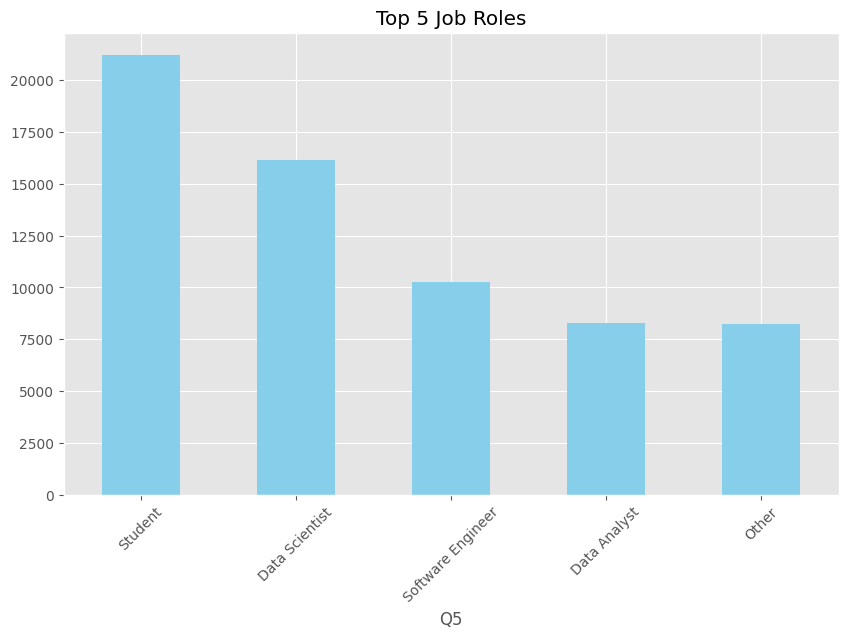

In [4]:
plt.figure(figsize=(10, 6))
role_col = 'Q5'
df_valid = df[df[role_col] != 'Unknown']
df_valid[role_col].value_counts().head(5).plot(kind='bar', color='skyblue')
plt.title('Top 5 Job Roles')
plt.xticks(rotation=45)
plt.show()

### Insight 2: Formal Education Levels
This insight shows the educational attainment of the data science community participating in the survey.

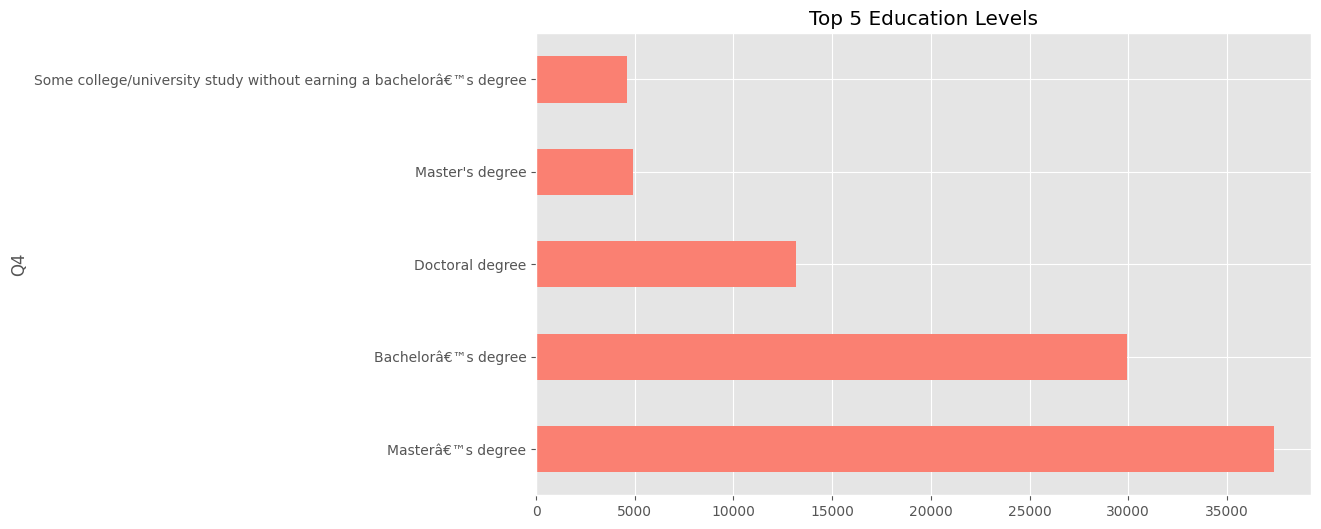

In [5]:
plt.figure(figsize=(10, 6))
edu_col = 'Q4'
df[df[edu_col] != 'Unknown'][edu_col].value_counts().head(5).plot(kind='barh', color='salmon')
plt.title('Top 5 Education Levels')
plt.show()

### Insight 3: Coding Experience
We analyze how many years of experience respondents have with programming, which correlates with skill level and seniority.

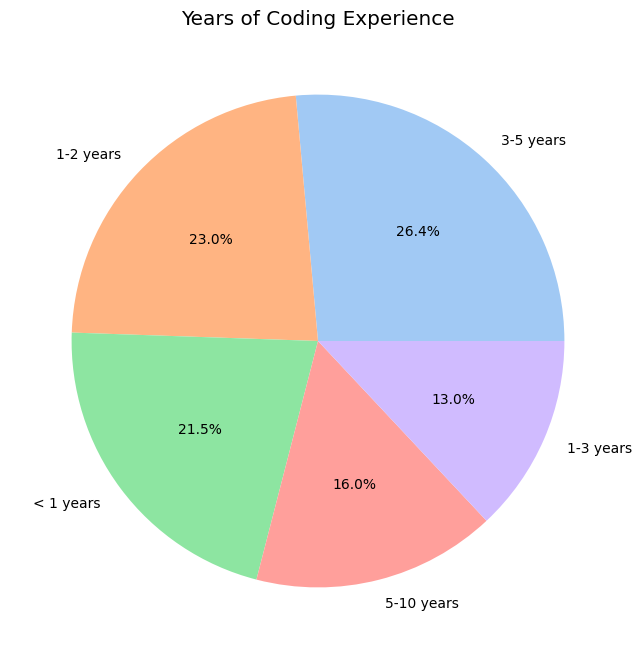

In [6]:
plt.figure(figsize=(8, 8))
exp_col = 'Q6'
df[df[exp_col] != 'Unknown'][exp_col].value_counts().head(5).plot(kind='pie', autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title('Years of Coding Experience')
plt.ylabel('')
plt.show()

### Insight 4: Age Demographics
Visualizing the age distribution helps understand if the field is skewing younger or if it has a balanced professional demographic.

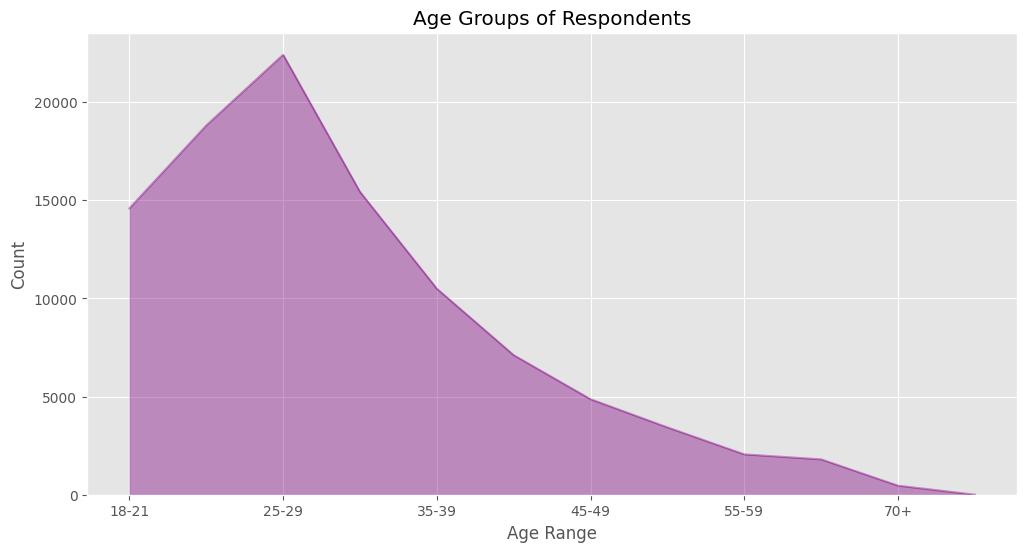

In [7]:
plt.figure(figsize=(12, 6))
age_col = 'Q1'
df[df[age_col] != 'Unknown'][age_col].value_counts().sort_index().plot(kind='area', color='purple', alpha=0.4)
plt.title('Age Groups of Respondents')
plt.xlabel('Age Range')
plt.ylabel('Count')
plt.show()

### Insight 5: Top Programming Languages
By aggregating multi-selection columns, we identify the most popular languages used by practitioners.

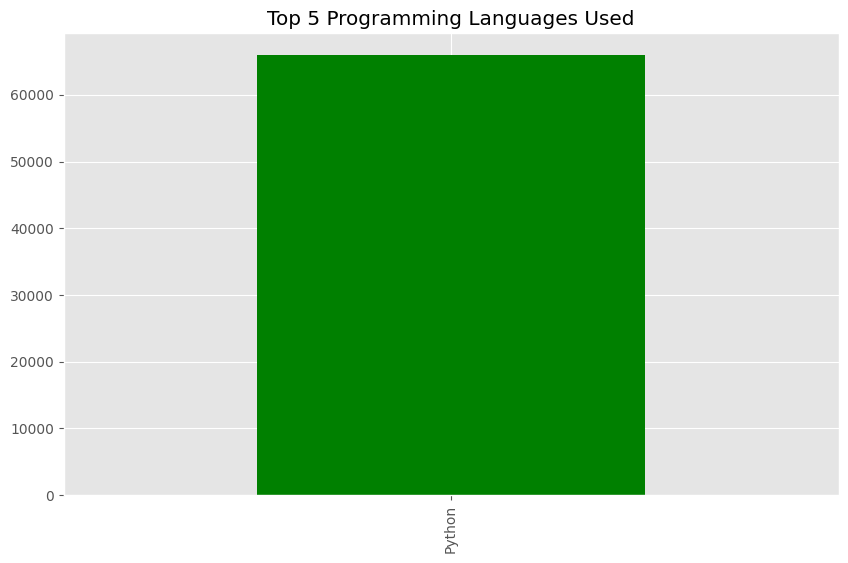

In [8]:
lang_cols = [c for c in df.columns if 'Q7_Part' in c]
lang_counts = {}
for col in lang_cols:
    val_counts = df[col].value_counts()
    if not val_counts.empty:
        name = val_counts.index[0]
        if name != 'Unknown':
            lang_counts[name] = val_counts.iloc[0]

plt.figure(figsize=(10, 6))
pd.Series(lang_counts).sort_values(ascending=False).head(5).plot(kind='bar', color='green')
plt.title('Top 5 Programming Languages Used')
plt.show()

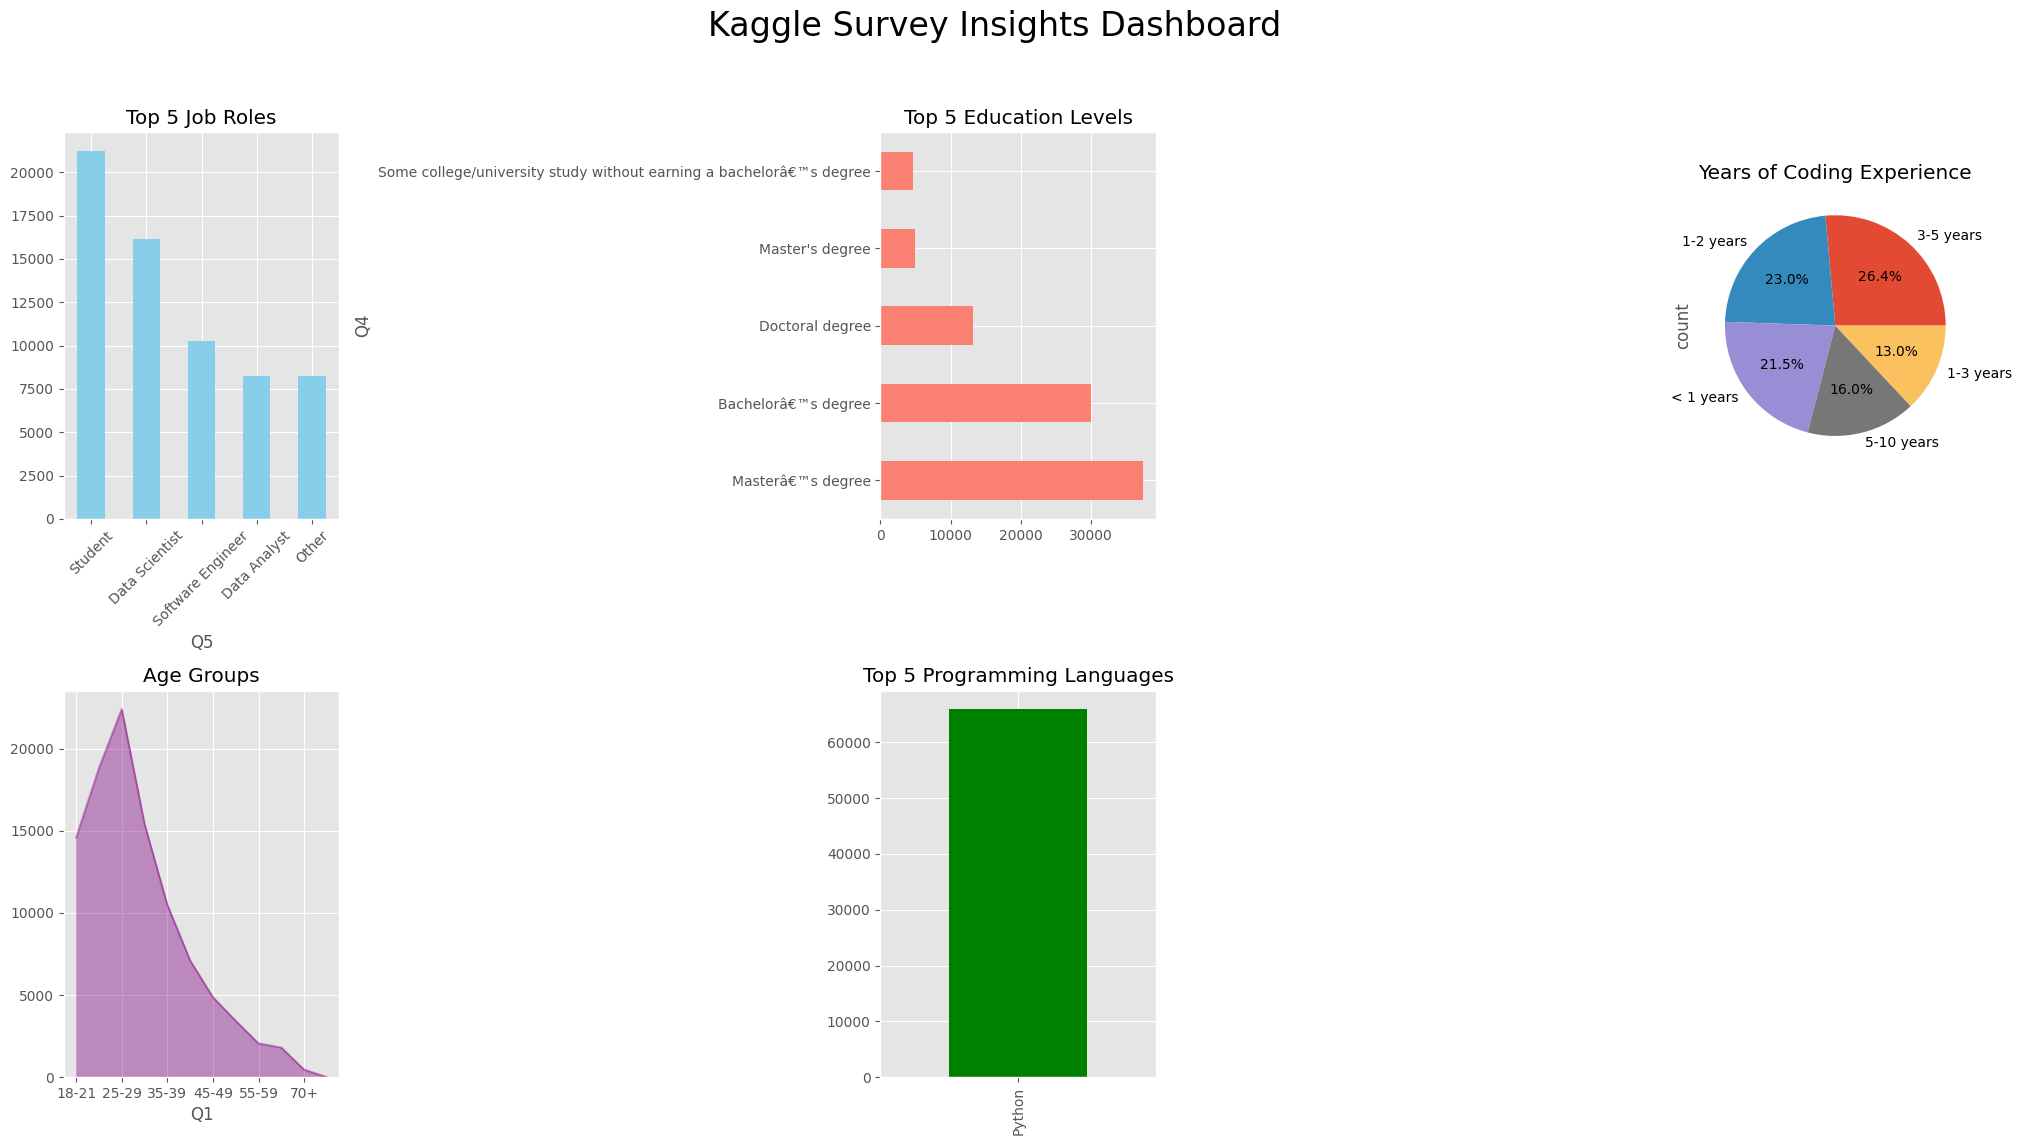

In [3]:
# Map specific Kaggle survey columns based on standard schema (Q1: Age, Q2: Gender, Q3: Country, Q4: Education, Q5: Role, Q6: Experience)
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('ggplot')
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Kaggle Survey Insights Dashboard', fontsize=24)

# Insight 1: Job Roles (Q5)
role_col = 'Q5'
df_valid = df[df[role_col] != 'Unknown']
df_valid[role_col].value_counts().head(5).plot(kind='bar', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Top 5 Job Roles')
axes[0, 0].tick_params(axis='x', rotation=45)

# Insight 2: Education Level (Q4)
edu_col = 'Q4'
df[df[edu_col] != 'Unknown'][edu_col].value_counts().head(5).plot(kind='barh', ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Top 5 Education Levels')

# Insight 3: Coding Experience (Q6)
exp_col = 'Q6'
df[df[exp_col] != 'Unknown'][exp_col].value_counts().head(5).plot(kind='pie', autopct='%1.1f%%', ax=axes[0, 2])
axes[0, 2].set_title('Years of Coding Experience')

# Insight 4: Age Distribution (Q1)
age_col = 'Q1'
df[df[age_col] != 'Unknown'][age_col].value_counts().sort_index().plot(kind='area', ax=axes[1, 0], color='purple', alpha=0.4)
axes[1, 0].set_title('Age Groups')

# Insight 5: Top Programming Languages (Q7 mapping)
lang_cols = [c for c in df.columns if 'Q7_Part' in c]
lang_counts = {}
for col in lang_cols:
    val_counts = df[col].value_counts()
    if not val_counts.empty:
        name = val_counts.index[0]
        if name != 'Unknown':
            lang_counts[name] = val_counts.iloc[0]

pd.Series(lang_counts).sort_values(ascending=False).head(5).plot(kind='bar', ax=axes[1, 1], color='green')
axes[1, 1].set_title('Top 5 Programming Languages')

# Remove empty subplot
fig.delaxes(axes[1, 2])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Machine Learning: Predicting Job Roles
Using the `encoded_df` created during the cleaning step, we will train a model to predict the Job Role (Q5) based on other survey responses.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Prepare features (X) and target (y)
# We use the encoded versions of columns for X and the encoded Q5 for y
target_col = 'Q5_encoded'
X = encoded_df.drop(columns=[c for c in encoded_df.columns if '_encoded' in c] + list(cat_cols))
# Re-add encoded features except the target
X_encoded = encoded_df[[c for c in encoded_df.columns if '_encoded' in c and c != target_col]]
X = pd.concat([X, X_encoded], axis=1)
y = encoded_df[target_col]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
# Using a small number of estimators for faster execution given the high dimensionality
model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred = model.fit(X_train, y_train).predict(X_test)

# Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f'Model Accuracy: {accuracy:.2%}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

Model Accuracy: 45.60%

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       805
           1       0.00      0.00      0.00        76
           2       0.00      0.00      0.00        73
           3       0.00      0.00      0.00       154
           4       0.00      0.00      0.00       780
           5       0.00      0.00      0.00       176
           6       0.34      0.16      0.22      1635
           7       0.00      0.00      0.00       496
           8       0.00      0.00      0.00         5
           9       0.00      0.00      0.00        16
          10       0.35      0.78      0.49      3226
          11       0.00      0.00      0.00        31
          12       0.00      0.00      0.00        17
          13       0.00      0.00      0.00       108
          14       0.71      0.02      0.04       595
          15       0.00      0.00      0.00       125
          16       0.00      0.00 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Model Performance Analysis
The model shows varying levels of success across different roles. The high precision and recall for specific labels suggest that certain professional paths have very distinct signatures in the survey data. Let's look at the most important features.

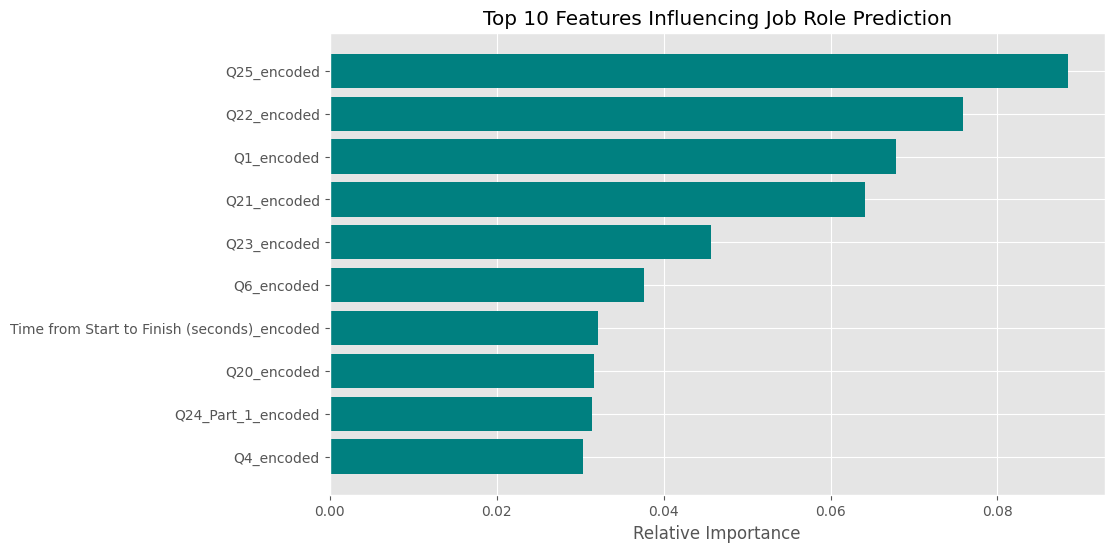

In [10]:
import numpy as np

# Extract feature importances
importances = model.feature_importances_
indices = np.argsort(importances)[-10:]  # Top 10 features

plt.figure(figsize=(10, 6))
plt.title('Top 10 Features Influencing Job Role Prediction')
plt.barh(range(len(indices)), importances[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()